## Data

Dataset source: https://www.kaggle.com/datasets/catherinerasgaitis/mxmh-survey-results

The data was collected via an online survay and contains the following attributes:
1. Timestamp
2. Age
3. Primary streaming service
4. Hours per day
5. While working
6. Instrumentalist
7. Composer
8. Fav genre
9. Exploratory
10. Foreign languages
11. BPM
12. Frequency [Classical]
13. Frequency [Country]
14. Frequency [EDM]
15. Frequency [Folk]
16. Frequency [Gospel]
17. Frequency [Hip hop]
18. Frequency [Jazz]
19. Frequency [K pop]
20. Frequency [Latin]
21. Frequency [Lofi]
22. Frequency [Metal]
23. Frequency [Pop]
24. Frequency [R&B]
25. Frequency [Rap]
26. Frequency [Rock]
27. Frequency [Video game music]
28. Anxiety
29. Depression
30. Insomnia
31. OCD
32. Music effects
33. Permissions



In [88]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
df = pd.read_csv("datasets/mxmh_survey_results.csv")


The "Frequency [Genre]" columns are not considered because many of them are very sparse and may also contain redundant information w.r.t the participants' favorite genre due to similarity between the genres (our assumptions is that someone who listenes two rock will likely more often listen to metal as well).

In [89]:
num_rows = df.shape[0]
print(f"Total number of rows is {num_rows}")
frequency_columns = []
for column in df.columns:
    if "Frequency" in column:
        num_never = (np.array(df[column]) == "Never").sum()
        print(f"{column} sparcity ratio: {round((num_never/num_rows)*100, 2)}%")
        frequency_columns.append(column)
df = df.drop(frequency_columns, axis=1)

Total number of rows is 736
Frequency [Classical] sparcity ratio: 22.96%
Frequency [Country] sparcity ratio: 46.6%
Frequency [EDM] sparcity ratio: 41.71%
Frequency [Folk] sparcity ratio: 39.67%
Frequency [Gospel] sparcity ratio: 72.69%
Frequency [Hip hop] sparcity ratio: 24.59%
Frequency [Jazz] sparcity ratio: 35.46%
Frequency [K pop] sparcity ratio: 56.52%
Frequency [Latin] sparcity ratio: 60.19%
Frequency [Lofi] sparcity ratio: 38.04%
Frequency [Metal] sparcity ratio: 35.87%
Frequency [Pop] sparcity ratio: 7.61%
Frequency [R&B] sparcity ratio: 30.57%
Frequency [Rap] sparcity ratio: 27.17%
Frequency [Rock] sparcity ratio: 12.36%
Frequency [Video game music] sparcity ratio: 32.07%


The age of the participants of the study is very unevenly distributed with an ovewhelming majority of participants being in their late teens and twenties. This fact should be kept in mind when considering the results of our experiments on the data. Nevertheless, this combined with the fact that we are interested mostly in studying the direction of the causal relation between music taste and self-reported mental illness leads us to also exclude this column. Further columns that were excluded due to their lack of importance to our goals are: Timestamp, Primary streaming service, Foreign Languages, Permissions and Music effects.

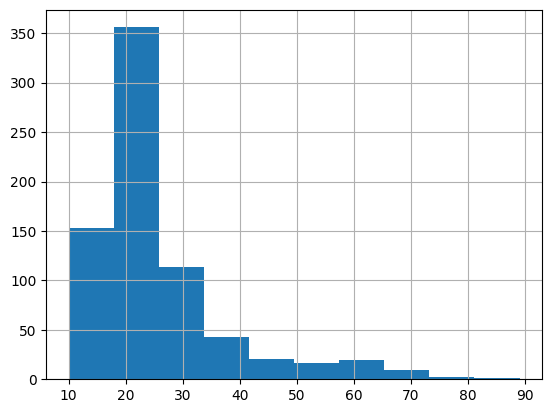

In [90]:
df["Age"].hist()
df = df.drop(["Age", "Foreign languages", "Permissions", "Music effects", "Timestamp", "Primary streaming service"], axis = 1)

This leaves us with the following columns:

In [91]:
df.columns

Index(['Hours per day', 'While working', 'Instrumentalist', 'Composer',
       'Fav genre', 'Exploratory', 'BPM', 'Anxiety', 'Depression', 'Insomnia',
       'OCD'],
      dtype='object')

Due to the way the data was collected (via an online survay) we also assume that many of the entries contain inconsistent information.
For this reason we decide to filter some of the data before accounting for outliers. For example some entries include BPM (beats per minute) values that exceed 1000. Since the highest standard tempo marking (Prestissimo) is 200 BPM and we suppose that some newer musical genres might still slightly exceed that, we remove entries with BPM larger than 300.

In [92]:
df.describe()

,Hours per day,BPM,Anxiety,Depression,Insomnia,OCD
count,736.000000,6.290000e+02,736.000000,736.000000,736.000000,736.000000
mean,3.572758,1.589948e+06,5.837636,4.796196,3.738451,2.637228
std,3.028199,3.987261e+07,2.793054,3.028870,3.088689,2.842017
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,2.000000,1.000000e+02,4.000000,2.000000,1.000000,0.000000
50%,3.000000,1.200000e+02,6.000000,5.000000,3.000000,2.000000
75%,5.000000,1.440000e+02,8.000000,7.000000,6.000000,5.000000
max,24.000000,1.000000e+09,10.000000,10.000000,10.000000,10.000000


In [93]:
df = df[df['BPM'] <= 300]
df.describe()

,Hours per day,BPM,Anxiety,Depression,Insomnia,OCD
count,627.000000,627.000000,627.000000,627.000000,627.000000,627.000000
mean,3.705263,122.625199,5.879585,4.878788,3.817384,2.645933
std,3.088820,33.905830,2.768536,3.005928,3.113749,2.855379
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,100.000000,4.000000,2.000000,1.000000,0.000000
50%,3.000000,120.000000,6.000000,5.000000,3.000000,2.000000
75%,5.000000,143.500000,8.000000,7.000000,6.000000,5.000000
max,24.000000,220.000000,10.000000,10.000000,10.000000,10.000000


The following is a standard removal of rows with N/A values and outliers with a zscore higher than 3

In [94]:
df = df.dropna(axis=0)
df = df[(np.abs(stats.zscore(df[['Hours per day', 'BPM']])) < 3).all(axis=1)]
df.describe()

,Hours per day,BPM,Anxiety,Depression,Insomnia,OCD
count,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000
mean,3.497865,123.929392,5.859606,4.857143,3.774220,2.635468
std,2.504096,32.072440,2.759924,2.976904,3.088126,2.840489
min,0.000000,40.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,100.000000,4.000000,2.000000,1.000000,0.000000
50%,3.000000,120.000000,6.000000,5.000000,3.000000,2.000000
75%,5.000000,144.000000,8.000000,7.000000,6.000000,5.000000
max,12.000000,220.000000,10.000000,10.000000,10.000000,10.000000


Finally, in order to make the data on self-reported mental illness easier to interpret, we bin the data with the following mapping for anxiety, depression and insomnia:
* 0-1 -> 0
* 1-4 -> 1
* 4-7 -> 2
* 7-10 -> 10

This also allows us to more easily relate our results to existing studies on said illnesses. In particular, we consider three studies from American National Center for Health and Statistics: [1](https://www.cdc.gov/nchs/products/databriefs/db379.htm#:~:text=The%20total%20percentage%20of%20adults,those%20aged%2065%20and%20over.) and [2](https://www.cdc.gov/nchs/products/databriefs/db378.htm), which study the symptom of depression and generalized anxiety in adults, regard participants as having "None or minimal", "Mild", "Moderate" or "Severe" depression and anxiety symptoms respectively. [3](https://www.cdc.gov/nchs/products/databriefs/db462.htm) is a study on sleep medication use which discusses its usefulness in cases of insomnia. Here participants' use of sleep medication is also split in 4 categories: "Never", "Some days", "Most days" and "Every day"

On the other hand, we group participants as either having (1) or not having (0) OCD, which also corresponds to the way it is regarded in the literature (e.g. [4](https://www.sciencedirect.com/science/article/pii/S0278584605003465)). We use the following mapping:
* 0-3 -> 0
* 3-10 -> 1

In [95]:
labels = [0, 1, 2, 3]
bins = [0,1, 3, 7, 10]
#Average is 2.6
#Todo: maybe visualize averages
ocd_bins = [0, 3, 10]
ocd_labels = [0, 1]

# Create a new column with mapped categories
df['Anxiety'] = pd.cut(df['Anxiety'], bins=bins, labels=labels, include_lowest=True, right=True)
df['Depression'] = pd.cut(df['Depression'], bins=bins, labels=labels, include_lowest=True, right=True)
df['Insomnia'] = pd.cut(df['Insomnia'], bins=bins, labels=labels, include_lowest=True, right=True)
df['OCD'] = pd.cut(df['OCD'], bins=ocd_bins, labels=ocd_labels, include_lowest=True, right=True)


In [97]:
df.to_csv("datasets/mxmh_clean.csv", index=False)